# Control óptimo de EDOs — Clase 7
**Bang-bang y arcos singulares**

FCEN–UBA. Bibliografía principal: Lenhart & Workman, *Optimal Control Applied to Biological Models* (2007).

> Convención del curso: problemas de **máximo** y Hamiltoniano $H = L + \lambda f$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, solve_bvp
from scipy.optimize import brentq, minimize
plt.rcParams.update({'figure.figsize': (7, 3.5), 'axes.grid': True, 'grid.alpha': 0.3})

In [2]:
def rk4(F, y0, t):
    """Integra y' = F(t, y) en la grilla t con Runge-Kutta 4."""
    y = np.zeros((len(t), np.size(y0))); y[0] = y0
    for k in range(len(t) - 1):
        h = t[k+1] - t[k]
        k1 = F(t[k], y[k]); k2 = F(t[k] + h/2, y[k] + h/2*k1)
        k3 = F(t[k] + h/2, y[k] + h/2*k2); k4 = F(t[k] + h, y[k] + h*k3)
        y[k+1] = y[k] + h/6*(k1 + 2*k2 + 2*k3 + k4)
    return y

def fbsm(f, dlam, ucalc, x0, lamT, T, N=1000, m=1, u0=None,
         omega=0.5, tol=1e-3, maxit=2000, historia=False):
    """Forward-Backward Sweep (Lenhart & Workman, cap. 4). Problema de MÁXIMO.
    f(t,x,u)        -> x'                  (arreglos de dimensión n)
    dlam(t,x,u,lam) -> lam' = -H_x
    ucalc(t,x,lam)  -> control dado por el PMP (dimensión m)
    lamT(xT)        -> lam(T) (condición de transversalidad)
    Devuelve un diccionario con t, x, u, lam, iteraciones (y la historia de u)."""
    t = np.linspace(0, T, N+1); h = T/N
    x0 = np.atleast_1d(np.asarray(x0, float)); n = len(x0)
    u = np.zeros((N+1, m)) if u0 is None else np.array(u0, float).reshape(N+1, m)
    x = np.zeros((N+1, n)); lam = np.zeros((N+1, n)); hist = []
    rel = lambda a, b: np.sum(np.abs(a - b)) / max(np.sum(np.abs(a)), 1e-12)
    for it in range(maxit):
        uo, xo, lo = u.copy(), x.copy(), lam.copy()
        x[0] = x0                                   # Paso 1: estado hacia adelante
        for k in range(N):
            um = 0.5*(u[k] + u[k+1])
            k1 = f(t[k], x[k], u[k]); k2 = f(t[k]+h/2, x[k]+h/2*k1, um)
            k3 = f(t[k]+h/2, x[k]+h/2*k2, um); k4 = f(t[k]+h, x[k]+h*k3, u[k+1])
            x[k+1] = x[k] + h/6*(k1 + 2*k2 + 2*k3 + k4)
        lam[N] = lamT(x[N])                         # Paso 2: adjunto hacia atrás
        for k in range(N, 0, -1):
            um = 0.5*(u[k] + u[k-1]); xm = 0.5*(x[k] + x[k-1])
            k1 = dlam(t[k], x[k], u[k], lam[k])
            k2 = dlam(t[k]-h/2, xm, um, lam[k] - h/2*k1)
            k3 = dlam(t[k]-h/2, xm, um, lam[k] - h/2*k2)
            k4 = dlam(t[k]-h, x[k-1], u[k-1], lam[k] - h*k3)
            lam[k-1] = lam[k] - h/6*(k1 + 2*k2 + 2*k3 + k4)
        u1 = np.array([np.atleast_1d(ucalc(t[k], x[k], lam[k])) for k in range(N+1)]).reshape(N+1, m)
        u = omega*u1 + (1 - omega)*uo               # Paso 3: actualizar con relajación
        if historia: hist.append(u.copy())
        if it > 0 and max(rel(u, uo), rel(x, xo), rel(lam, lo)) < tol:   # Paso 4
            break
    return dict(t=t, x=x, u=u, lam=lam, iters=it+1, hist=hist)

def integral(v, t):
    """Regla del trapecio."""
    return float(np.sum(0.5*(v[1:] + v[:-1])*np.diff(t)))

def directo(f, fx, fu, L, Lx, Lu, x0, T, N, cotas, phi=None, dphi=None, u0=None):
    """Método directo (Euler + L-BFGS-B), gradiente por adjunto discreto. Caso escalar."""
    h = T/N; t = np.linspace(0, T, N+1)
    def sim(u):
        x = np.zeros(N+1); x[0] = x0
        for k in range(N):
            x[k+1] = x[k] + h*f(t[k], x[k], u[k])
        return x
    def menosJ(u):
        x = sim(u)
        J = h*sum(L(t[k], x[k], u[k]) for k in range(N)) + (phi(x[N]) if phi else 0.0)
        p = dphi(x[N]) if dphi else 0.0; g = np.zeros(N)
        for k in range(N-1, -1, -1):
            g[k] = h*(Lu(t[k], x[k], u[k]) + p*fu(t[k], x[k], u[k]))
            p = p*(1 + h*fx(t[k], x[k], u[k])) + h*Lx(t[k], x[k], u[k])
        return -J, -g
    u0 = np.full(N, 0.5*(cotas[0] + cotas[1])) if u0 is None else u0
    r = minimize(menosJ, u0, jac=True, method='L-BFGS-B', bounds=[cotas]*N, options={'maxiter': 5000})
    return t, sim(r.x), r.x, -r.fun

## 1. La fábrica con FBSM bang-bang
$\max\int_0^T(1-u)x$, $\dot x=kux$, $0\le u\le1$. Función de conmutación $\psi=x(k\lambda-1)$.
Teoría: $u^*=1$ en $[0,T-1/k)$, $0$ después.

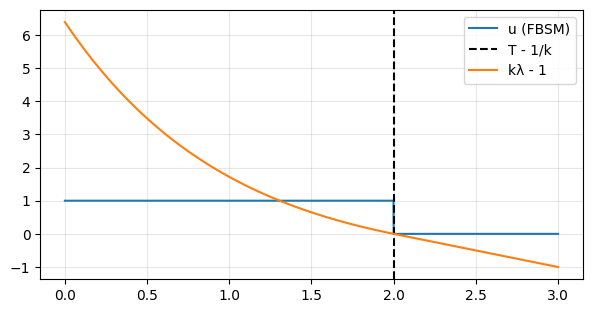

iteraciones: 22  J numérico = 7.389049654768034   J teórico = e^(kT-1)/k = 7.38905609893065


In [3]:
k, T = 1.0, 3.0
r = fbsm(lambda t, x, u: k*u*x, lambda t, x, u, l: -(1 - u) - l*k*u,
         lambda t, x, l: 1.0 if x[0]*(k*l[0] - 1) > 0 else 0.0,
         1.0, lambda xT: np.zeros(1), T, N=3000, omega=0.5, tol=1e-6)
plt.plot(r['t'], r['u'][:, 0], label='u (FBSM)'); plt.axvline(T - 1/k, ls='--', c='k', label='T - 1/k')
plt.plot(r['t'], k*r['lam'][:, 0] - 1, label='kλ - 1'); plt.legend(); plt.show()
J = integral((1 - r['u'][:, 0])*r['x'][:, 0], r['t'])
print('iteraciones:', r['iters'], ' J numérico =', J, '  J teórico = e^(kT-1)/k =', np.exp(k*T - 1)/k)

## 2. Ejemplo 17.3: arco singular
$\min\int_0^2(x-t^2)^2$, $\dot x=u$, $0\le u\le4$, $x(0)=1$. Teoría: $u^*=0$ en $[0,1)$ y $u^*=2t$ (singular) en $(1,2]$.

**(a) FBSM con la regla del signo de $\psi=\lambda$:** oscila, porque sobre el arco singular $\lambda\approx 0$
y el signo cambia de iteración en iteración ("chattering numérico").

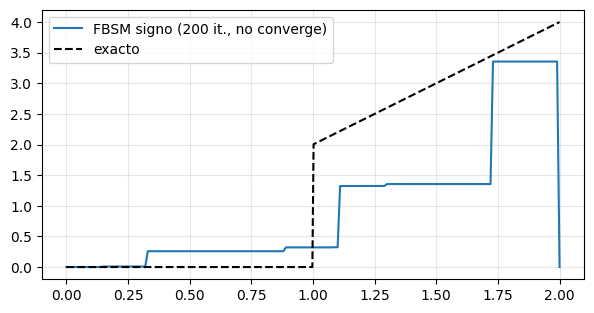

In [4]:
r = fbsm(lambda t, x, u: u + 0*x, lambda t, x, u, l: 2*(x - t**2),
         lambda t, x, l: 4.0 if l[0] > 0 else 0.0, 1.0, lambda xT: np.zeros(1), 2.0,
         N=200, omega=0.5, maxit=200, tol=1e-6)
t_ex = np.linspace(0, 2, 400)
plt.plot(r['t'], r['u'][:, 0], label=f'FBSM signo ({r["iters"]} it., no converge)')
plt.plot(t_ex, np.where(t_ex < 1, 0, 2*t_ex), 'k--', label='exacto'); plt.legend(); plt.show()

**(b) Método directo:** no necesita saber nada del arco singular.
(El último control $u_{N-1}$ no afecta al objetivo discreto, así que no lo graficamos.)

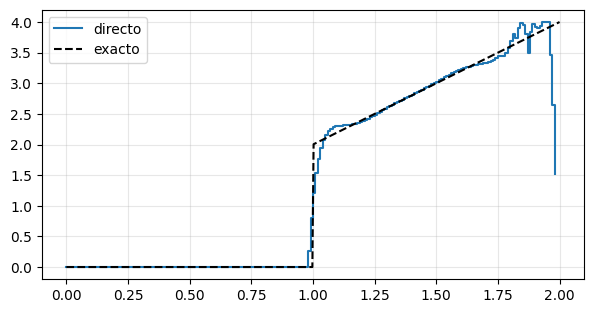

J numérico = -0.5383573122932916    J exacto = -8/15 = -0.5333333333333333


In [5]:
t, x, u, J = directo(lambda t, x, u: u, lambda t, x, u: 0.0, lambda t, x, u: 1.0,
                     lambda t, x, u: -(x - t**2)**2, lambda t, x, u: -2*(x - t**2), lambda t, x, u: 0.0,
                     1.0, 2.0, 200, (0, 4), u0=np.zeros(200))
plt.step(t[:-2], u[:-1], where='post', label='directo'); plt.plot(t_ex, np.where(t_ex < 1, 0, 2*t_ex), 'k--', label='exacto')
plt.legend(); plt.show()
print('J numérico =', J, '   J exacto = -8/15 =', -8/15)

## 3. Pesca y rendimiento máximo sostenible
$\max\int_0^{10}ux$, $\dot x=x(1-x)-ux$, $0\le u\le u_{\max}$, $x(0)=0.2$.
Teoría: $u=0$ hasta $t=\ln 4$, singular $x=\frac12$, $u=\frac12$, y $u=u_{\max}$ en los últimos $2$ unidades de tiempo (si $u_{\max}=1$).

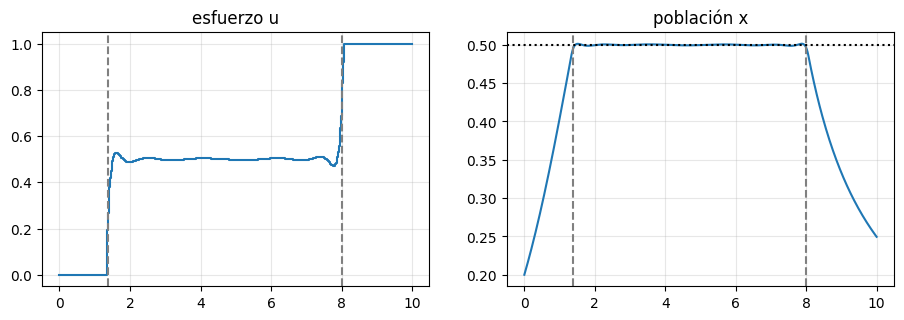

J = 2.3464190567076706 | en el arco singular: x medio = 0.49996086135981654  u medio = 0.5005626715452206


In [6]:
def pesca(umax, N=500, T=10.0, x0=0.2):
    return directo(lambda t, x, u: x*(1 - x) - u*x, lambda t, x, u: 1 - 2*x - u, lambda t, x, u: -x,
                   lambda t, x, u: u*x, lambda t, x, u: u, lambda t, x, u: x, x0, T, N, (0, umax))
t, x, u, J = pesca(1.0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].step(t[:-1], u, where='post'); ax[0].set_title('esfuerzo u')
ax[1].plot(t, x); ax[1].axhline(0.5, ls=':', c='k'); ax[1].set_title('población x')
for a in ax:
    for s in (np.log(4), 8): a.axvline(s, ls='--', c='gray')
plt.show()
mask = (t[:-1] > 2.5) & (t[:-1] < 7.5)
print('J =', J, '| en el arco singular: x medio =', x[:-1][mask].mean(), ' u medio =', u[mask].mean())

Si $u_{\max}<r/2=0.5$ el control singular **no es admisible**. ¿Qué estructura aparece?

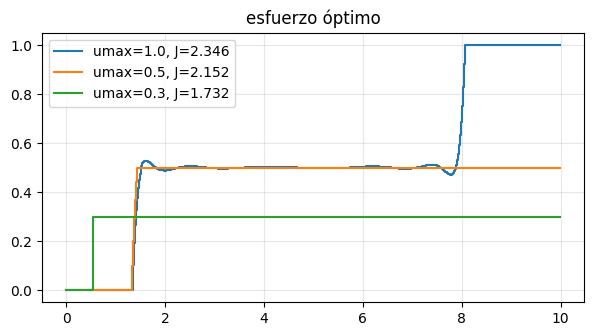

In [7]:
for umax in [1.0, 0.5, 0.3]:
    t, x, u, J = pesca(umax)
    plt.step(t[:-1], u, where='post', label=f'umax={umax}, J={J:.3f}')
plt.legend(); plt.title('esfuerzo óptimo'); plt.show()

## Para explorar
1. Fábrica: ¿qué pasa si $kT<1$? Verificar que $u^*\equiv0$.
2. Pesca con descuento: integrando $e^{-\rho t}ux$. Repetir con $\rho=0.1$ y $0.5$. ¿Dónde queda el arco singular?
   (Teoría: $x_s$ resuelve $r(1-2x/k)=\rho$, es decir $x_s=\frac k2(1-\rho/r)$.)
3. Ejercicio 3 de la clase ($\max\int_0^1(2x-u)$, $\dot x=-x+u$, $0\le u\le 2$): verificar la conmutación en $t=1-\ln 2$.